# USCityURL Orlando Resilience EDA Demo

This notebook uses USCityURL to locate Orlando's official municipal website, discover resilience-related pages, extract usable text, and perform preliminary exploratory data analysis.

## Demo workflow

1. Load USCityURL and select Orlando.
2. Crawl a limited number of pages on the official Orlando website.
3. Filter links using resilience-related keywords.
4. Extract and clean text from a small sample.
5. Check extraction quality and perform preliminary EDA.

## 1. Setup



In [13]:
import io
import re
import time
from urllib.parse import urldefrag, urljoin, urlsplit, urlunsplit

import pymupdf
import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display

USCITYURL_CSV = "https://raw.githubusercontent.com/caimeng2/UScityURL/master/UScityURL.csv"
MAX_PAGES_TO_CRAWL = 60
MAX_DOCUMENTS_TO_ANALYZE = 15
REQUEST_TIMEOUT = 15
REQUEST_DELAY = 0.15

HEADERS = {
    "User-Agent": "CMSE495-USCityURL-Demo/1.0 (educational research)"
}
session = requests.Session()
session.headers.update(HEADERS)

plt.style.use("seaborn-v0_8-whitegrid")
print("Demo limits:", MAX_PAGES_TO_CRAWL, "crawl pages and", MAX_DOCUMENTS_TO_ANALYZE, "documents")

Demo limits: 60 crawl pages and 15 documents


## 2. Locate Orlando with USCityURL

USCityURL supplies the official municipal website for Orlando, Florida.

In [14]:
cities = pd.read_csv(USCITYURL_CSV)

required_columns = {"MUNICIPALITY", "STATE", "WEBSITE_URL"}
missing_columns = required_columns.difference(cities.columns)
if missing_columns:
    raise ValueError(f"USCityURL is missing required columns: {sorted(missing_columns)}")

orlando_rows = cities.loc[
    cities["MUNICIPALITY"].astype(str).str.strip().str.casefold().eq("orlando")
    & cities["STATE"].astype(str).str.strip().str.casefold().eq("florida")
]

if len(orlando_rows) != 1:
    raise ValueError(f"Expected one Orlando, Florida row; found {len(orlando_rows)}")

base_url = orlando_rows.iloc[0]["WEBSITE_URL"]
official_host = urlsplit(base_url).netloc.lower()

print("USCityURL records:", f"{len(cities):,}")
print("Selected city: Orlando, Florida")
print("Official website:", base_url)

USCityURL records: 19,518
Selected city: Orlando, Florida
Official website: https://www.orlando.gov/


## 3. Discover resilience-related links

The crawler stays on the official Orlando domain and identifies candidate links from their anchor text and URL.

In [15]:
RESILIENCE_KEYWORDS = [
    "resilience", "resiliency", "hazard", "mitigation", "climate",
    "adaptation", "emergency", "flood", "hurricane", "storm",
    "sustainability", "future ready", "comprehensive plan", "master plan",
]
SKIP_EXTENSIONS = (".jpg", ".jpeg", ".png", ".gif", ".svg", ".zip", ".mp4", ".mp3")
SKIP_HOSTS = {"facebook.com", "www.facebook.com", "twitter.com", "x.com", "maps.google.com"}

def normalize_url(url):
    """Return a stable URL without fragments or tracking/language queries."""
    clean_url, _ = urldefrag(str(url))
    parts = urlsplit(clean_url)
    path = parts.path or "/"
    return urlunsplit((parts.scheme.lower(), parts.netloc.lower(), path, "", ""))

def fetch(url):
    """Request one public page and return the response or an error message."""
    try:
        response = session.get(url, timeout=REQUEST_TIMEOUT, allow_redirects=True)
        response.raise_for_status()
        return response, None
    except requests.RequestException as error:
        return None, f"{type(error).__name__}: {error}"

def page_links(page_url, html):
    """Collect usable links and their visible anchor text from one HTML page."""
    soup = BeautifulSoup(html, "html.parser")
    found = []
    for anchor in soup.find_all("a", href=True):
        raw_url = anchor["href"].strip()
        if raw_url.startswith(("mailto:", "tel:", "javascript:")):
            continue
        full_url = normalize_url(urljoin(page_url, raw_url))
        parts = urlsplit(full_url)
        if parts.netloc in SKIP_HOSTS or parts.path.lower().endswith(SKIP_EXTENSIONS):
            continue
        found.append({"anchor_text": anchor.get_text(" ", strip=True), "url": full_url})
    return found

to_visit = [normalize_url(base_url)]
visited = set()
collected_links = []
crawl_failures = []

while to_visit and len(visited) < MAX_PAGES_TO_CRAWL:
    current_url = to_visit.pop(0)
    if current_url in visited:
        continue
    visited.add(current_url)

    response, error = fetch(current_url)
    if error:
        crawl_failures.append({"url": current_url, "error": error})
        continue

    links = page_links(response.url, response.text)
    collected_links.extend(links)
    for item in links:
        link_host = urlsplit(item["url"]).netloc.lower()
        if link_host == official_host and item["url"] not in visited and item["url"] not in to_visit:
            to_visit.append(item["url"])
    time.sleep(REQUEST_DELAY)

links_df = pd.DataFrame(collected_links).drop_duplicates(subset="url")
links_df = links_df.loc[
    links_df["url"].apply(lambda url: urlsplit(url).netloc.lower() == official_host)
].copy()
links_df["search_text"] = (links_df["anchor_text"].fillna("") + " " + links_df["url"]).str.casefold()
links_df["keywords_found"] = links_df["search_text"].apply(
    lambda text: [keyword for keyword in RESILIENCE_KEYWORDS if keyword in text]
)
relevant_links = links_df.loc[links_df["keywords_found"].str.len() > 0].copy()
planning_phrases = ["resilience plan", "comprehensive plan", "hazard mitigation", "climate action"]
relevant_links["relevance_score"] = relevant_links.apply(
    lambda row: len(row["keywords_found"])
    + 3 * sum(phrase in row["search_text"] for phrase in planning_phrases),
    axis=1,
)
relevant_links = relevant_links.sort_values(
    ["relevance_score", "anchor_text"], ascending=[False, True]
).reset_index(drop=True)

print("Pages visited:", len(visited))
print("Unique links collected:", f"{len(links_df):,}")
print("Candidate resilience links:", len(relevant_links))
print("Crawl failures:", len(crawl_failures))
display(relevant_links[["anchor_text", "url", "keywords_found"]].head(10))

Pages visited: 60
Unique links collected: 736
Candidate resilience links: 21
Crawl failures: 2


,anchor_text,url,keywords_found
0,Orlando Resilience Plan,https://www.orlando.gov/Our-Government/Orlando...,[resilience]
1,"Volunteer with the Office of Sustainability, R...",https://www.orlando.gov/Community-Programs-Eve...,"[resilience, sustainability, future ready]"
2,Apply for a Flood Permit Do you want to build ...,https://www.orlando.gov/Building-Development/P...,"[hazard, flood]"
3,AIPO T50/T51 Four Industrial Warehouses Master...,https://www.orlando.gov/Building-Development/M...,[master plan]
4,Apply for a Tree Removal or Encroachment Permi...,https://www.orlando.gov/Building-Development/P...,[hazard]
5,Become a Police Department Emergency Communica...,https://www.orlando.gov/Public-Safety/OPD/Beco...,[emergency]
6,Become an Orlando Fire Department Emergency Co...,https://www.orlando.gov/Public-Safety/OFD/Beco...,[emergency]
7,Community Development Block Grants & Emergency...,https://www.orlando.gov/Building-Development/H...,[emergency]
8,Emergency Operation Center,https://www.orlando.gov/Our-Government/Departm...,[emergency]
9,Find out if you live in a Floodplain,https://www.orlando.gov/Parks-the-Environment/...,[flood]


## 4. Extract and check a small document sample

The demo extracts up to 15 HTML or PDF candidates, checks text quality, and removes exact duplicates before analysis.

In [16]:
def clean_text(text):
    return re.sub(r"\s+", " ", text or "").strip()

def extract_document(row):
    response, error = fetch(row["url"])
    result = {
        "title": row["anchor_text"] or row["url"],
        "url": row["url"],
        "keywords_found": row["keywords_found"],
        "status": "failed" if error else "ok",
        "http_status": None if response is None else response.status_code,
        "format": "unknown",
        "extraction_method": "none",
        "error": error,
        "text": "",
    }
    if response is None:
        return result

    content_type = response.headers.get("Content-Type", "").lower()
    is_pdf = "pdf" in content_type or response.content.startswith(b"%PDF")
    try:
        if is_pdf:
            with pymupdf.open(stream=io.BytesIO(response.content), filetype="pdf") as pdf:
                text = " ".join(page.get_text("text") for page in pdf)
            result["format"] = "PDF"
            result["extraction_method"] = "PyMuPDF"
        else:
            soup = BeautifulSoup(response.text, "html.parser")
            for tag in soup(["script", "style", "nav", "header", "footer"]):
                tag.decompose()
            main_content = soup.find("main") or soup.find("article") or soup.body or soup
            text = main_content.get_text(" ", strip=True)
            result["format"] = "HTML"
            result["extraction_method"] = "BeautifulSoup"
        result["text"] = clean_text(text)
    except Exception as extraction_error:
        result["status"] = "failed"
        result["error"] = f"{type(extraction_error).__name__}: {extraction_error}"
    return result

sample_links = relevant_links.head(MAX_DOCUMENTS_TO_ANALYZE)
documents = pd.DataFrame([extract_document(row) for _, row in sample_links.iterrows()])
documents["word_count"] = documents["text"].str.findall(r"\b[\w'-]+\b").str.len()
documents["quality"] = documents["word_count"].apply(
    lambda count: "Failed" if count == 0 else ("Short - review" if count < 100 else "Usable")
)
documents["normalized_text"] = documents["text"].str.casefold().str.replace(r"\s+", " ", regex=True)
documents["exact_duplicate"] = documents["normalized_text"].duplicated(keep="first")

analysis_df = documents.loc[
    documents["quality"].eq("Usable") & ~documents["exact_duplicate"]
].copy()

display(documents[["title", "format", "word_count", "quality", "exact_duplicate"]])
print("Usable unique documents for EDA:", len(analysis_df))

,title,format,word_count,quality,exact_duplicate
0,Orlando Resilience Plan,HTML,627,Usable,False
1,"Volunteer with the Office of Sustainability, R...",HTML,0,Failed,False
2,Apply for a Flood Permit Do you want to build ...,HTML,344,Usable,False
3,AIPO T50/T51 Four Industrial Warehouses Master...,HTML,323,Usable,False
4,Apply for a Tree Removal or Encroachment Permi...,HTML,446,Usable,False
5,Become a Police Department Emergency Communica...,HTML,780,Usable,False
6,Become an Orlando Fire Department Emergency Co...,HTML,729,Usable,False
7,Community Development Block Grants & Emergency...,HTML,820,Usable,False
8,Emergency Operation Center,HTML,22,Short - review,False
9,Find out if you live in a Floodplain,HTML,528,Usable,False


Usable unique documents for EDA: 13


## 5. Preliminary EDA

The plots show overall topic mentions and topic concentration by document. Results describe only the collected sample.

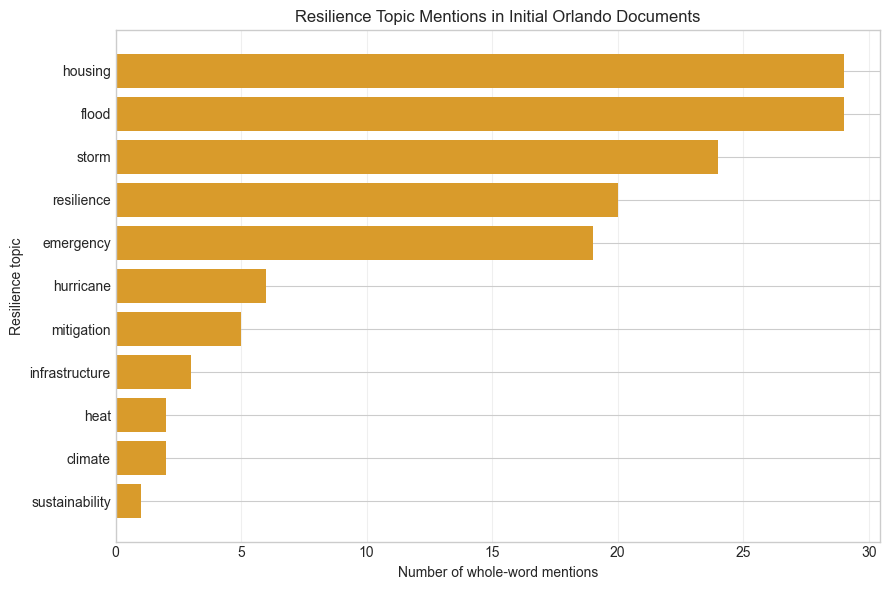

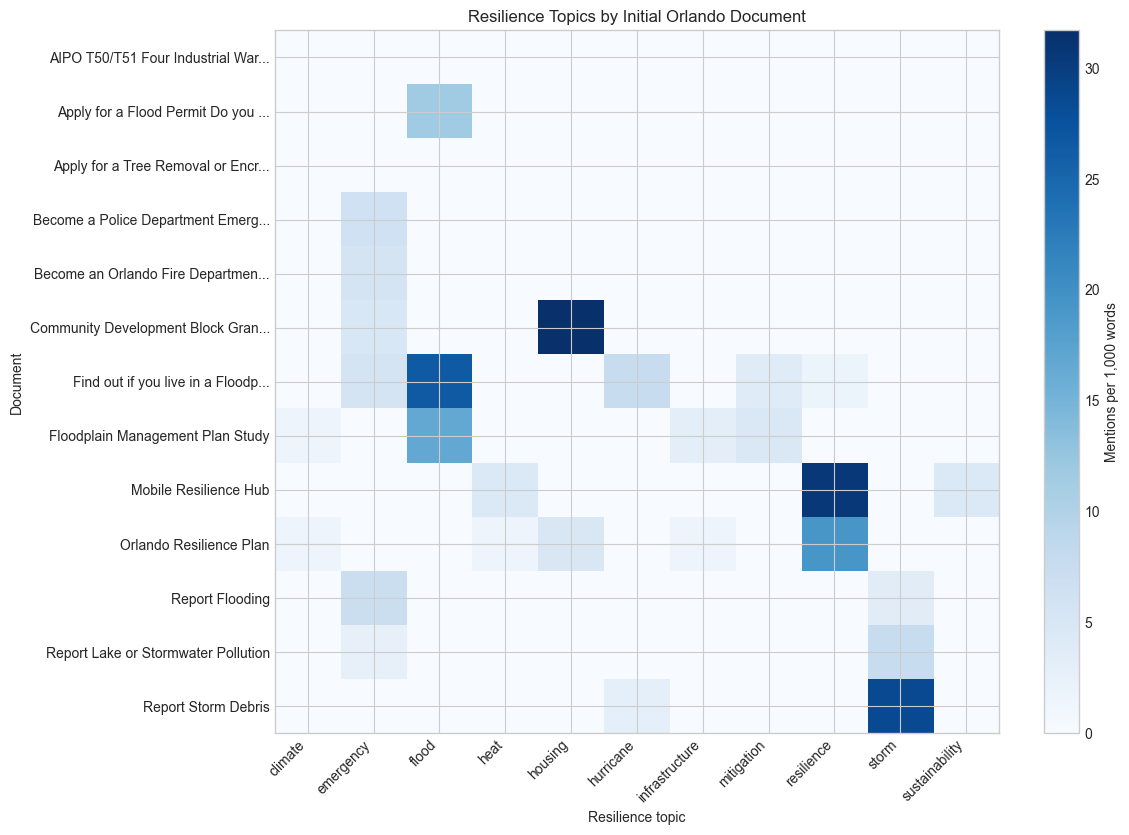

,topic,mentions
0,flood,29
1,housing,29
2,storm,24
3,resilience,20
4,emergency,19
5,hurricane,6
6,mitigation,5
7,infrastructure,3
8,climate,2
9,heat,2


In [17]:
if analysis_df.empty:
    raise RuntimeError("No usable documents were extracted. Review the candidate and failure tables above.")

TOPICS = [
    "resilience", "climate", "flood", "hurricane", "storm",
    "heat", "housing", "infrastructure", "emergency", "mitigation", "sustainability",
]

def count_topic(text, topic):
    pattern = rf"(?<!\w){re.escape(topic)}(?!\w)"
    return len(re.findall(pattern, text or "", flags=re.IGNORECASE))


# Plot 1: total resilience-topic mentions
topic_counts = {
    topic: sum(count_topic(text, topic) for text in analysis_df["text"])
    for topic in TOPICS
}
topic_df = pd.DataFrame(
    topic_counts.items(), columns=["topic", "mentions"]
).sort_values("mentions", ascending=False)
topic_plot = topic_df.sort_values("mentions")

plt.figure(figsize=(9, 6))
plt.barh(topic_plot["topic"], topic_plot["mentions"], color="#d99b2b")
plt.title("Resilience Topic Mentions in Initial Orlando Documents")
plt.xlabel("Number of whole-word mentions")
plt.ylabel("Resilience topic")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# Plot 2: topic mentions per 1,000 words in each document
topic_rows = []
for _, document in analysis_df.iterrows():
    for topic in TOPICS:
        mentions = count_topic(document["text"], topic)
        topic_rows.append({
            "document": document["title"],
            "topic": topic,
            "mentions_per_1000_words": mentions / document["word_count"] * 1000,
        })

document_topics = pd.DataFrame(topic_rows)
topic_matrix = document_topics.pivot(
    index="document",
    columns="topic",
    values="mentions_per_1000_words",
).fillna(0)
short_document_names = [
    title if len(title) <= 35 else title[:32] + "..."
    for title in topic_matrix.index
]

fig, ax = plt.subplots(figsize=(12, max(5, len(topic_matrix) * 0.65)))
heatmap = ax.imshow(topic_matrix.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(topic_matrix.columns)))
ax.set_xticklabels(topic_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(topic_matrix.index)))
ax.set_yticklabels(short_document_names)
ax.set_title("Resilience Topics by Initial Orlando Document")
ax.set_xlabel("Resilience topic")
ax.set_ylabel("Document")
colorbar = plt.colorbar(heatmap, ax=ax)
colorbar.set_label("Mentions per 1,000 words")
plt.tight_layout()
plt.show()

display(topic_df.reset_index(drop=True))

## 6. Demo summary

In [18]:
print("Pipeline complete")
print("- Orlando selected from USCityURL:", base_url)
print("- Pages visited:", len(visited))
print("- Candidate links found:", len(relevant_links))
print("- Documents sampled:", len(documents))
print("- Usable unique documents analyzed:", len(analysis_df))
print("- Most mentioned sample topic:", topic_df.iloc[0]["topic"], f"({topic_df.iloc[0]['mentions']} mentions)")

Pipeline complete
- Orlando selected from USCityURL: https://www.orlando.gov/
- Pages visited: 60
- Candidate links found: 21
- Documents sampled: 15
- Usable unique documents analyzed: 13
- Most mentioned sample topic: flood (29 mentions)
